ref：
* https://greglandrum.github.io/rdkit-blog/posts/2025-02-08-more-on-generalized-substructure-search.html
* https://greglandrum.github.io/rdkit-blog/posts/2021-08-03-generalized-substructure-search.html
* https://greglandrum.github.io/rdkit-blog/posts/2022-04-05-searching-with-generic-groups.html
* https://github.com/LingjieBao1998/cs1610_work/blob/main/query_substructure/query_sub.ipynb
* https://rdkit.blogspot.com/2018/02/introducing-substructlibrary.html

In [1]:
from rdkit import Chem
from rdkit.Chem import rdMolEnumerator
from rdkit.Chem import rdTautomerQuery
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.drawOptions.minFontSize = 10
Draw.SetComicMode(IPythonConsole.drawOptions)
from rdkit.Chem import rdDepictor
rdDepictor.SetPreferCoordGen(True)
import rdkit
print(rdkit.__version__)
import time
print(time.asctime())
import pandas as pd

2023.03.1
Thu Oct  9 17:52:44 2025


In [2]:
from rdkit.Chem import PandasTools

# 1. 读取 sdf 文件，直接得到 pandas DataFrame
# sdf_file = "../data/mol_nmrshift_nmrshiftdb2_2024_all_processed.sdf"  # 替换为你的 sdf 文件路径
df = pd.read_csv("../data/test_core_mol_nmr_mae.csv", index_col=0)

print(len(df))

# 2. 查看 DataFrame
df.head()

58


,SMILES,NMR1,NMR2,NMR3(prediction),NMR1_Peaks,mae,mape,mae_max,mape_max,mae_all,mape_all
0,O=C1C(C(O)=O)=CN(C2CC2)C3=C([N+]([O-])=O)C(NC4...,"175.4, 164.8, 153.5, 152.1, 151.8, 141.7, 134....","175.4, 164.8, 152.66 (d, JC-F = 254.7 Hz) 152....","[174.4, 107.6, 166.15, 142, 37.35, 6.8, 6.8, 1...","[175.4, 164.8, 153.5, 152.1, 151.8, 141.7, 134...",2.566429,0.044159,8.5,0.326733,35.930,0.618223
1,O=C1C(C(O)=O)=CN(C2CC2)C3=C4C(C(C=CC=C5)=C5N4)...,"176.8, 165.9, 156.6, 155.0, 148.0, 140.1, 130....","176.8, 165.9, 155.80 (d, JC-F = 248.4 Hz), 148...","[174.4, 107.6, 166.15, 142, 37.35, 6.8, 6.8, 1...","[176.8, 165.9, 156.6, 155.0, 148.0, 140.1, 130...",2.345833,0.035703,11.9,0.298969,42.225,0.642650
2,O=C1C(C(O)=O)=CN(C2CC2)C3=C([N+]([O-])=O)C(C4=...,"175.4, 164.6, 156.2, 154.9, 153.0, 141.5, 130....","175.4, 164.6, 155.6 (d, JC-F = 248.2 Hz), 153....","[174.4, 107.6, 166.15, 142, 37.35, 6.8, 6.8, 1...","[175.4, 164.6, 156.2, 154.9, 153.0, 141.5, 130...",3.025000,0.045534,11.0,0.352381,48.400,0.728550
3,O=C1C(C(O)=O)=CN(C2CC2)C3=C(N)C(C4=CC=CS4)=C(F...,"176.7, 176.7, 165.6, 158.8, 157.2, 151.1, 141....","176.7, 176.7, 165.6, 158.03 (d, JC-F = 243.8 H...","[174.4, 107.6, 166.15, 142, 37.35, 6.8, 6.8, 1...","[176.7, 176.7, 165.6, 158.8, 157.2, 151.1, 141...",3.060625,0.044897,11.3,0.333333,48.970,0.718356
4,O=C1C(C(O)=O)=CN(C2CC2)C3=C(F)C(N4CCN(C)CC4)=C...,"179.2, 165.4, 150.0, 141.2, 140.1, 138.6, 138....","179.2, 165.4, 150.0, 140.7 (d, JC-F = 234.0 Hz...","[180.1, 107.6, 166.15, 142, 37.35, 6.8, 6.8, 1...","[179.2, 165.4, 150.0, 141.2, 140.1, 138.6, 138...",1.715000,0.036321,5.9,0.200000,24.010,0.508499


In [3]:
def strard_mol_fn(smiles):
    try:
        new_smiles = Chem.MolToSmiles(Chem.MolFromSmiles(Chem.MolToSmiles(Chem.MolFromSmiles(smiles))))
        return new_smiles
    except Exception as e:
        print(e)
        return ""

In [4]:
df["cano_smiles"] = df["SMILES"].apply(strard_mol_fn)

In [11]:
df

,SMILES,NMR1,NMR2,NMR3(prediction),NMR1_Peaks,mae,mape,mae_max,mape_max,mae_all,mape_all,cano_smiles
0,O=C1C(C(O)=O)=CN(C2CC2)C3=C([N+]([O-])=O)C(NC4...,"175.4, 164.8, 153.5, 152.1, 151.8, 141.7, 134....","175.4, 164.8, 152.66 (d, JC-F = 254.7 Hz) 152....","[174.4, 107.6, 166.15, 142, 37.35, 6.8, 6.8, 1...","[175.4, 164.8, 153.5, 152.1, 151.8, 141.7, 134...",2.566429,0.044159,8.500,0.326733,35.930,0.618223,O=C(O)c1cn(C2CC2)c2c([N+](=O)[O-])c(Nc3ccccc3)...
1,O=C1C(C(O)=O)=CN(C2CC2)C3=C4C(C(C=CC=C5)=C5N4)...,"176.8, 165.9, 156.6, 155.0, 148.0, 140.1, 130....","176.8, 165.9, 155.80 (d, JC-F = 248.4 Hz), 148...","[174.4, 107.6, 166.15, 142, 37.35, 6.8, 6.8, 1...","[176.8, 165.9, 156.6, 155.0, 148.0, 140.1, 130...",2.345833,0.035703,11.900,0.298969,42.225,0.642650,O=C(O)c1cn(C2CC2)c2c(cc(F)c3c4ccccc4[nH]c32)c1=O
2,O=C1C(C(O)=O)=CN(C2CC2)C3=C([N+]([O-])=O)C(C4=...,"175.4, 164.6, 156.2, 154.9, 153.0, 141.5, 130....","175.4, 164.6, 155.6 (d, JC-F = 248.2 Hz), 153....","[174.4, 107.6, 166.15, 142, 37.35, 6.8, 6.8, 1...","[175.4, 164.6, 156.2, 154.9, 153.0, 141.5, 130...",3.025000,0.045534,11.000,0.352381,48.400,0.728550,O=C(O)c1cn(C2CC2)c2c([N+](=O)[O-])c(-c3ccccc3)...
3,O=C1C(C(O)=O)=CN(C2CC2)C3=C(N)C(C4=CC=CS4)=C(F...,"176.7, 176.7, 165.6, 158.8, 157.2, 151.1, 141....","176.7, 176.7, 165.6, 158.03 (d, JC-F = 243.8 H...","[174.4, 107.6, 166.15, 142, 37.35, 6.8, 6.8, 1...","[176.7, 176.7, 165.6, 158.8, 157.2, 151.1, 141...",3.060625,0.044897,11.300,0.333333,48.970,0.718356,Nc1c(-c2cccs2)c(F)cc2c(=O)c(C(=O)O)cn(C3CC3)c12
4,O=C1C(C(O)=O)=CN(C2CC2)C3=C(F)C(N4CCN(C)CC4)=C...,"179.2, 165.4, 150.0, 141.2, 140.1, 138.6, 138....","179.2, 165.4, 150.0, 140.7 (d, JC-F = 234.0 Hz...","[180.1, 107.6, 166.15, 142, 37.35, 6.8, 6.8, 1...","[179.2, 165.4, 150.0, 141.2, 140.1, 138.6, 138...",1.715000,0.036321,5.900,0.200000,24.010,0.508499,CNc1c(F)c(N2CCN(C)CC2)c(F)c2c1c(=O)c(C(=O)O)cn...
5,O=C1C(C(O)=O)=CN(C2CC2)C3=CC(N4CCN(C)CC4)=C(F)...,"179.5, 166.2, 151.2, 149.6, 147.4, 140.2, 126....","179.5, 166.2, 151.2, 149.6, 147.4, 140.2, 125....","[180.1, 107.6, 166.15, 142, 37.35, 6.8, 6.8, 1...","[179.5, 166.2, 151.2, 149.6, 147.4, 140.2, 126...",3.087333,0.068988,17.210,0.595502,46.310,1.034826,Cc1c(F)c(N2CCN(C)CC2)cc2c1c(=O)c(C(=O)O)cn2C1CC1
6,O=C1C(C(O)=O)=CN(C2CC2)C3=C([N+]([O-])=O)C(Cl)...,"174.9, 164.3, 154.8, 153.2, 153.0, 140.6, 131....","174.9, 164.3, 154.00 (d, JC-F = 251.3 Hz), 153...","[174.4, 107.6, 166.15, 142, 37.35, 6.8, 6.8, 1...","[174.9, 164.3, 154.8, 153.2, 153.0, 140.6, 131...",3.620417,0.057910,11.000,0.364486,43.445,0.694922,O=C(O)c1cn(C2CC2)c2c([N+](=O)[O-])c(Cl)c(F)cc2...
7,O=C1C(C(O)=O)=CN(C2CC2)C3=C(F)C(N4CCN(C)CC4)=C...,"179.3, 165.3, 150.1, 139.8, 139.0, 136.8, 136....","179.3, 165.3, 150.1, 139.8, 139.0, 136.81 (d, ...","[180.1, 107.6, 166.15, 142, 37.35, 6.8, 6.8, 1...","[179.3, 165.3, 150.1, 139.8, 139.0, 136.8, 136...",1.748889,0.030377,5.800,0.190476,31.480,0.546779,CN1CCN(c2c(F)c(NCc3ccccc3)c3c(=O)c(C(=O)O)cn(C...
8,O=C1C(C(O)=O)=CN(C2CC2)C3=CC(N4CCN(C)CC4)=C(C)...,"179.0, 166.3, 151.3, 149.7, 147.3, 144.4, 144....","179.0, 166.3, 150.47 (d, JC-F = 244.2 Hz), 147...","[180.1, 107.6, 166.15, 142, 37.35, 6.8, 6.8, 1...","[179.0, 166.3, 151.3, 149.7, 147.3, 144.4, 144...",8.364118,0.131439,47.300,0.477961,142.190,2.234469,CCc1c(C)c(N2CCN(C)CC2)cc2c1c(=O)c(C(=O)O)cn2C1CC1
9,O=C1C(C(O)=O)=CN(CC)C2=CC(N3CCN(C)CC3)=C(F)C(C...,"179.3, 179.3, 166.5, 151.2, 149.5, 147.9, 144....","179.3 (d, JC-F = 3.0 Hz), 166.5, 150.34 (d, JC...","[180.1, 108.25, 163.7, 146.8, 48.3, 14.3, 141....","[179.3, 179.3, 166.5, 151.2, 149.5, 147.9, 144...",1.657333,0.018398,8.600,0.083333,24.860,0.275975,CCn1cc(C(=O)O)c(=O)c2c(C)c(F)c(N3CCN(C)CC3)cc21


In [12]:
from tqdm import tqdm
t1=time.time()
data = []
for idx in tqdm(df.index):
    smi = df.loc[idx, "cano_smiles"]
    mol = Chem.MolFromSmiles(smi)
    if not ((idx+1)%50000):
        print(f"Processed {idx+1} molecules in {(time.time()-t1):.1f} seconds")
    if mol is None: #or mol.GetNumAtoms()>50
        continue
    fp = Chem.PatternFingerprint(mol,fpSize=1024,tautomerFingerprints=True)
    data.append((smi,fp))
t2=time.time()

100%|██████████| 58/58 [00:00<00:00, 864.38it/s]


In [13]:
from rdkit.Chem import rdSubstructLibrary
t1=time.time()
mols = rdSubstructLibrary.CachedTrustedSmilesMolHolder()
fps = rdSubstructLibrary.TautomerPatternHolder(1024)
for smi,fp in data:
    mols.AddSmiles(smi)
    fps.AddFingerprint(fp)
library = rdSubstructLibrary.SubstructLibrary(mols,fps)
t2=time.time()
print(f"That took {t2-t1:.2f} seconds. The library has {len(library)} molecules.")

That took 0.00 seconds. The library has 58 molecules.


In [14]:
# library_save_path = "data/chemb_ssslib.pkl"
import pickle
library_save_path = "../data/test_core_mol_nmr_mae_ssslib.pkl"
pickle.dump(library,open(library_save_path,'wb'))

In [15]:
len(library)

58

In [16]:
indices_1 = library.GetMatches(Chem.MolFromSmiles('O=C1C(C(O)=O)=CNC2=CC=CC=C12'),maxResults=50000)
print(len(indices_1))

53


In [17]:
indices_2 = library.GetMatches(Chem.MolFromSmiles('O=C1C(C(O)=O)=CNC2=NC=CC=C12'),maxResults=50000)
print(len(indices_2))

2


In [18]:
for i in range(58):
    if i not in indices_1 and i not in indices_2:
        print(i)

41
43
53


In [21]:
indices_1 = library.GetMatches(Chem.MolFromSmiles('O=C1C(C(O(C))=O)=CNC2=CC=CC=C12'),maxResults=50000)#额外增加一个C
print(len(indices_1))

1


In [22]:
indices_2 = library.GetMatches(Chem.MolFromSmiles('O=C1C(C(O(C))=O)=CNC2=NC=CC=C12'),maxResults=50000)#额外增加一个C
print(len(indices_2))

0


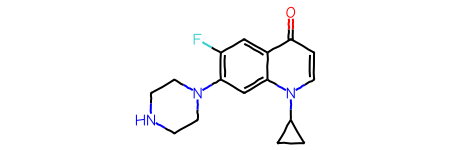

In [66]:
library.GetMol(53)